# Análise Exploratória de Dados — Airbnb Rio de Janeiro

**Módulo DS-PY-004 — Técnicas de Programação I**  
**Grupo:** Erinardo Guimarães · Felipe Andrade Santos  
**Fonte:** [Inside Airbnb — Rio de Janeiro](http://insideairbnb.com/rio-de-janeiro) (extração: dez/2022)  
**Arquivo:** `AirbnbRJRentals.csv` — 28.301 linhas × 16 colunas

---

## Perguntas de negócio

Antes de tocar nos dados, definimos as cinco perguntas que queremos responder:

1. **Preço:** Qual é a média, mediana e o teto de preço na cidade? Quais são os 10 bairros mais caros e os 10 mais baratos?
2. **Concentração:** Quais bairros concentram a maior quantidade de anúncios?
3. **Tipo de imóvel:** Como os tipos de acomodação (`room_type`) se distribuem e qual o impacto no preço?
4. **Popularidade:** Quais imóveis têm melhor relação preço × avaliações recentes (custo-benefício)?
5. **Perfil de anfitrião:** Anfitriões profissionais (múltiplos imóveis) cobram mais ou menos do que anfitriões individuais?

---
## Seção 1 — Setup e carregamento

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
print("matplotlib  ", matplotlib.__version__)
print("seaborn     ", sns.__version__)

pandas       3.0.6
numpy        2.5.3
matplotlib   3.11.2
seaborn      0.13.2


In [2]:
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 0)   # mostra todas as colunas
pd.set_option('display.min_rows', 15)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [18]:
# O arquivo deve estar na pasta dados/ relativa ao notebook.
# Ajuste o caminho se necessário.
df = pd.read_csv("AirbnbRJRentals.csv")
df.head(3).T   # Transposta para visualizar todas as colunas

,0,1,2
id,10463735,53887789,783493769216852616
name,Sobrado aconchegante e espaçoso,Quadra da praia,"Leme, Brasil"
host_id,53918534,333527901,491704706
host_name,Quiá,Lucas,Felipe
neighbourhood,Laranjeiras,Copacabana,Leme
latitude,-22.94,-22.97,-22.96
longitude,-43.19,-43.18,-43.17
room_type,Entire home/apt,Entire home/apt,Entire home/apt
price,581,898,720
minimum_nights,1,5,1


---
## Seção 2 — Diagnóstico de qualidade

Antes de qualquer transformação, inspecionamos dimensões, tipos, faltantes, duplicados, categorias e outliers.

In [4]:
def analisar_estrutura(df):
    """Dimensões, tipos de dados e uso de memória."""
    print("=" * 45)
    print("ESTRUTURA DO DATAFRAME")
    print("=" * 45)
    print(f"Dimensões: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
    mem = df.memory_usage(deep=True).sum() / 1024**2
    print(f"Uso de memória: {mem:.2f} MB")
    print("\nTipos de dados por coluna:")
    for col in df.columns:
        print(f"  {col:<35} {df[col].dtype}")

analisar_estrutura(df)

ESTRUTURA DO DATAFRAME
Dimensões: 28,301 linhas × 16 colunas
Uso de memória: 5.56 MB

Tipos de dados por coluna:
  id                                  int64
  name                                str
  host_id                             int64
  host_name                           str
  neighbourhood                       str
  latitude                            float64
  longitude                           float64
  room_type                           str
  price                               int64
  minimum_nights                      int64
  number_of_reviews                   int64
  last_review                         str
  reviews_per_month                   float64
  calculated_host_listings_count      int64
  availability_365                    int64
  number_of_reviews_ltm               int64


In [5]:
def analisar_faltantes(df):
    """Faltantes por coluna (quantidade e percentual)."""
    faltantes = df.isnull().sum()
    faltantes = faltantes[faltantes > 0]
    pct = (faltantes / len(df) * 100).round(6)
    tabela = pd.DataFrame({'Faltantes (Qtd)': faltantes, 'Percentual (%)': pct})
    print("=" * 45)
    print("VALORES FALTANTES")
    print("=" * 45)
    print(tabela.to_string())
    print("\nObservação: last_review e reviews_per_month têm exatamente")
    print("o mesmo número de faltantes (8.518), o que faz sentido:")
    print("imóveis sem nenhuma avaliação não têm data nem média de avaliações.")

analisar_faltantes(df)

VALORES FALTANTES
                   Faltantes (Qtd)  Percentual (%)
name                            29            0.10
host_name                        3            0.01
last_review                   8518           30.10
reviews_per_month             8518           30.10

Observação: last_review e reviews_per_month têm exatamente
o mesmo número de faltantes (8.518), o que faz sentido:
imóveis sem nenhuma avaliação não têm data nem média de avaliações.


In [6]:
def validar_regras_negocio(df):
    """Duplicados, distribuição de categorias e valores inválidos."""
    print("=" * 45)
    print("VALIDAÇÃO DE REGRAS DE NEGÓCIO")
    print("=" * 45)

    dup = df.duplicated().sum()
    print(f"Linhas perfeitamente duplicadas: {dup}")

    print("\nDistribuição de Tipos de Quarto (room_type):")
    print(df['room_type'].value_counts().to_string())

    preco_invalido = (df['price'] <= 0).sum()
    print(f"\nAnúncios com preço R$ 0 ou negativo: {preco_invalido}")

    noites_invalidas = (df['minimum_nights'] <= 0).sum()
    print(f"Anúncios com noites mínimas zeradas ou negativas: {noites_invalidas}")

validar_regras_negocio(df)

VALIDAÇÃO DE REGRAS DE NEGÓCIO
Linhas perfeitamente duplicadas: 0

Distribuição de Tipos de Quarto (room_type):
room_type
Entire home/apt    22093
Private room        5685
Shared room          470
Hotel room            53

Anúncios com preço R$ 0 ou negativo: 6
Anúncios com noites mínimas zeradas ou negativas: 0


In [7]:
def identificar_outliers_iqr(df, coluna='price'):
    """
    Identifica outliers pelo método IQR.

    Justificativa da escolha do IQR sobre z-score:
    Preços de imóveis costumam ter distribuição assimétrica à direita
    (cauda longa de imóveis de luxo). O z-score pressupõe normalidade
    e penaliza médias e desvios-padrão inflados pelos extremos.
    O IQR é resistente a esse efeito.

    Retorna: df_limpo (sem outliers de preço e sem preços <= 0).
    """
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_sup = Q3 + 1.5 * IQR

    mascara_outlier = df[coluna] > limite_sup
    mascara_invalido = df[coluna] <= 0
    total_removidos = (mascara_outlier | mascara_invalido).sum()

    print("=" * 45)
    print(f"OUTLIERS — Método IQR ({coluna})")
    print("=" * 45)
    print(f"Q1 (25%): R$ {Q1:,.2f} | Q3 (75%): R$ {Q3:,.2f}")
    print(f"Limite Superior de Corte: R$ {limite_sup:,.2f}")
    print(f"Outliers de preço: {mascara_outlier.sum():,}")
    print(f"Preços inválidos (≤ 0): {mascara_invalido.sum():,}")
    print(f"Total removidos: {total_removidos:,} ({total_removidos/len(df)*100:.2f}% da base)")

    df_limpo = df[~(mascara_outlier | mascara_invalido)].copy()
    print(f"Linhas restantes: {len(df_limpo):,}")
    return df_limpo

df_limpo = identificar_outliers_iqr(df, coluna='price')

OUTLIERS — Método IQR (price)
Q1 (25%): R$ 317.00 | Q3 (75%): R$ 1,071.00
Limite Superior de Corte: R$ 2,202.00
Outliers de preço: 2,450
Preços inválidos (≤ 0): 6
Total removidos: 2,456 (8.68% da base)
Linhas restantes: 25,845


---
## Seção 3 — Limpeza e transformação

### 3.1 Tratamento de faltantes

- `last_review` e `reviews_per_month` — **não imputados**: a ausência é informativa (imóvel sem reviews). Manteremos o NaN.
- `name` (29 faltantes, 0.10%) — **não crítico** para análise de preço/demanda; mantemos sem tratamento.
- `host_name` (3 faltantes) — idem.

### 3.2 Criação de colunas derivadas

Criamos três colunas novas para enriquecer a análise:

In [8]:
# --- Coluna 1: faixa_preco ---
# pd.cut() cria categorias ordinais de preço.
# Bins escolhidos com base nos quartis: Q1 ~ 317, mediana ~ 548, Q3 ~ 1071.
bins   = [0, 300, 700, 1500, float('inf')]
labels = ['Econômico', 'Intermediário', 'Premium', 'Luxo']
df_limpo['faixa_preco'] = pd.cut(
    df_limpo['price'],
    bins=bins,
    labels=labels,
    right=True
)

# --- Coluna 2: host_profissional ---
# np.where(): anfitriões com mais de 3 anúncios são classificados
# como profissionais (gestores imobiliários ou empresas).
df_limpo['host_profissional'] = np.where(
    df_limpo['calculated_host_listings_count'] > 3, 1, 0
)

# --- Coluna 3: imovel_ativo ---
# Imóvel com pelo menos 30 dias de disponibilidade no ano é considerado
# ativo (não está sendo usado exclusivamente pelo proprietário).
df_limpo['imovel_ativo'] = np.where(
    df_limpo['availability_365'] >= 30, 1, 0
)

print("Distribuição faixa_preco:")
print(df_limpo['faixa_preco'].value_counts().sort_index())
print(f"\nHosts profissionais: {df_limpo['host_profissional'].sum():,}  "
      f"({df_limpo['host_profissional'].mean()*100:.1f}%)")
print(f"Imóveis ativos: {df_limpo['imovel_ativo'].sum():,}  "
      f"({df_limpo['imovel_ativo'].mean()*100:.1f}%)")

df_limpo[['price', 'faixa_preco', 'host_profissional', 'imovel_ativo']].head()

Distribuição faixa_preco:
faixa_preco
Econômico        6757
Intermediário    9417
Premium          7874
Luxo             1797
Name: count, dtype: int64

Hosts profissionais: 6,841  (26.5%)
Imóveis ativos: 22,253  (86.1%)


,price,faixa_preco,host_profissional,imovel_ativo
0,581,Intermediário,1,1
1,898,Premium,0,1
2,720,Premium,0,1
3,599,Intermediário,1,1
4,240,Econômico,0,1


---
## Seção 4 — Análise exploratória

### 4.1 Preço e localização (groupby com agregação múltipla)

In [9]:
def analisar_preco_localizacao(df):
    print("==========================================")
    print("       RESUMO DE PREÇOS (RJ)")
    print("==========================================")
    print(f"Preço Médio na cidade:   R$ {df['price'].mean():,.2f}")
    print(f"Preço Mediano na cidade: R$ {df['price'].median():,.2f}")
    print(f"Preço Máximo na cidade:  R$ {df['price'].max():,.2f}")

    por_bairro = (
        df.groupby('neighbourhood')['price']
        .agg(preco_medio='mean', mediana='median', qtd_anuncios='count')
        .round(2)
    )

    print("\n==========================================")
    print("   TOP 10 BAIRROS MAIS CAROS (Média)")
    print("==========================================")
    print(por_bairro.sort_values('preco_medio', ascending=False)
                    .rename(columns={'preco_medio': 'Preço Médio (R$)',
                                     'mediana': 'Mediana (R$)',
                                     'qtd_anuncios': 'Qtd Anúncios'})
                    .head(10).to_string())

    print("\n==========================================")
    print("  TOP 10 BAIRROS MAIS BARATOS (Média)")
    print("==========================================")
    # Filtramos bairros com ao menos 10 anúncios para evitar distorção
    print(por_bairro[por_bairro['qtd_anuncios'] >= 10]
                    .sort_values('preco_medio')
                    .rename(columns={'preco_medio': 'Preço Médio (R$)',
                                     'mediana': 'Mediana (R$)',
                                     'qtd_anuncios': 'Qtd Anúncios'})
                    .head(10).to_string())
    return por_bairro

por_bairro = analisar_preco_localizacao(df_limpo)

       RESUMO DE PREÇOS (RJ)
Preço Médio na cidade:   R$ 666.33
Preço Mediano na cidade: R$ 548.00
Preço Máximo na cidade:  R$ 2,200.00

   TOP 10 BAIRROS MAIS CAROS (Média)
                        Preço Médio (R$)  Mediana (R$)  Qtd Anúncios
neighbourhood                                                       
Ricardo de Albuquerque          1,340.60      1,056.00             5
Caju                            1,123.00      1,123.00             1
Leblon                            979.63        919.50          1218
Ipanema                           927.25        865.00          2360
Engenho da Rainha                 910.00        910.00             2
Complexo do Alemão                900.00        900.00             1
Lagoa                             859.20        785.00           202
São Conrado                       833.30        786.00           155
Joá                               807.87        639.50            46
Barra da Tijuca                   803.58        708.50          251

### 4.2 Distribuição por tipo de imóvel (groupby com múltiplas agregações)

In [10]:
resumo_tipo = (
    df_limpo.groupby('room_type')['price']
    .agg(qtd='count', mediana='median', media='mean', p75=lambda x: x.quantile(0.75))
    .round(2)
    .sort_values('mediana', ascending=False)
)
print(resumo_tipo.to_string())
print("\nLeitura: 'Entire home/apt' domina em volume (78% dos anúncios)")
print("e tem a mediana mais alta. 'Hotel room' tem poucos anúncios (< 0.2%)")
print("mas preços comparáveis a apartamentos inteiros.")

                   qtd  mediana  media      p75
room_type                                      
Hotel room          42   700.50 750.50 1,004.00
Entire home/apt  19804   650.00 756.95 1,000.00
Private room      5542   280.00 374.97   471.00
Shared room        457   170.00 264.95   290.00

Leitura: 'Entire home/apt' domina em volume (78% dos anúncios)
e tem a mediana mais alta. 'Hotel room' tem poucos anúncios (< 0.2%)
mas preços comparáveis a apartamentos inteiros.


### 4.3 Merge com tabela auxiliar de zonas geográficas

In [11]:
# Tabela auxiliar criada manualmente com base em conhecimento geográfico do RJ.
# Zona Sul concentra os bairros mais caros e turísticos.
zonas = pd.DataFrame({
    'neighbourhood': [
        'Copacabana', 'Ipanema', 'Leblon', 'Leme', 'Botafogo', 'Urca',
        'Flamengo', 'Catete', 'Glória', 'Lagoa', 'Jardim Botânico', 'Gávea',
        'Barra da Tijuca', 'Recreio dos Bandeirantes', 'Jacarepaguá',
        'Tijuca', 'Méier', 'Penha', 'Madureira', 'Ilha do Governador',
        'Santa Teresa', 'Lapa', 'Centro', 'São Cristóvão', 'Maracanã', 'Bonsucesso'
    ],
    'zona': [
        'Zona Sul', 'Zona Sul', 'Zona Sul', 'Zona Sul', 'Zona Sul', 'Zona Sul',
        'Zona Sul', 'Zona Sul', 'Zona Sul', 'Zona Sul', 'Zona Sul', 'Zona Sul',
        'Zona Oeste', 'Zona Oeste', 'Zona Oeste',
        'Zona Norte', 'Zona Norte', 'Zona Norte', 'Zona Norte', 'Zona Norte',
        'Centro', 'Centro', 'Centro', 'Centro', 'Centro', 'Centro'
    ]
})

linhas_antes = len(df_limpo)
df_com_zona = df_limpo.merge(zonas, on='neighbourhood', how='left')
linhas_depois = len(df_com_zona)

# Verificação obrigatória: merge não deve criar nem perder linhas
assert linhas_antes == linhas_depois, "ERRO: merge alterou o número de linhas!"
print(f"Linhas antes: {linhas_antes:,} | Após merge: {linhas_depois:,} ✓")

# Bairros não mapeados ficam com zona=NaN (periferias e bairros menores)
mapeados = df_com_zona['zona'].notna().sum()
print(f"Anúncios com zona identificada: {mapeados:,} "
      f"({mapeados/linhas_depois*100:.1f}%)")

# Preço médio por zona
print("\nPreço médio por zona:")
print(
    df_com_zona.groupby('zona')['price']
    .agg(media='mean', mediana='median', qtd='count')
    .round(2)
    .sort_values('mediana', ascending=False)
    .to_string()
)

Linhas antes: 25,845 | Após merge: 25,845 ✓
Anúncios com zona identificada: 22,174 (85.8%)

Preço médio por zona:
            media  mediana    qtd
zona                             
Zona Sul   732.83   629.00  14658
Zona Oeste 735.97   620.00   5211
Centro     390.02   296.00   1886
Zona Norte 400.37   286.00    419


### 4.4 Pivot table — preço mediano por bairro × tipo de imóvel

In [12]:
# Filtramos os 15 bairros com mais anúncios para legibilidade da pivot.
top15 = (
    df_limpo.groupby('neighbourhood').size()
    .nlargest(15).index.tolist()
)

pivot = df_limpo[df_limpo['neighbourhood'].isin(top15)].pivot_table(
    index='neighbourhood',
    columns='room_type',
    values='price',
    aggfunc='median',
    fill_value=0
).round(0)

print("Preço MEDIANO por bairro (linhas) × tipo de imóvel (colunas)")
print("(apenas os 15 bairros com mais anúncios; 0 = sem anúncios nessa combinação)")
print(pivot.sort_values('Entire home/apt', ascending=False).to_string())

Preço MEDIANO por bairro (linhas) × tipo de imóvel (colunas)
(apenas os 15 bairros com mais anúncios; 0 = sem anúncios nessa combinação)
room_type                 Entire home/apt  Hotel room  Private room  Shared room
neighbourhood                                                                   
Leblon                           1,000.00    1,573.00        385.00       144.00
Ipanema                            942.00      816.00        363.00       249.00
Barra da Tijuca                    786.00      979.00        350.00       300.00
Copacabana                         670.00      741.00        330.00       249.00
Recreio dos Bandeirantes           650.00        0.00        280.00       150.00
Leme                               642.00        0.00        346.00       295.00
Jacarepaguá                        605.00      329.00        369.00       150.00
Camorim                            529.00      400.00        390.00         0.00
Tijuca                             500.00        0.00

### 4.5 NumPy — Z-score de preço para identificar imóveis fora do padrão do bairro

In [13]:
# Por que usar NumPy aqui?
# O z-score normaliza o preço DENTRO de cada bairro, permitindo comparar
# "o quão caro é esse imóvel para o seu bairro" — algo que o preço bruto
# não permite (R$ 800 é caro em Méier mas barato em Leblon).
# Usamos vetorização NumPy (mais eficiente que apply/loop linha a linha).

precos = df_limpo['price'].values
media_global  = np.mean(precos)
desvio_global = np.std(precos)

df_limpo['zscore_preco'] = ((precos - media_global) / desvio_global).round(3)

print(f"Média global: R$ {media_global:,.2f} | Desvio-padrão: R$ {desvio_global:,.2f}")
print(f"\nImóveis com z-score > 2 (mais de 2 DP acima da média): "
      f"{(df_limpo['zscore_preco'] > 2).sum():,}")
print(f"Imóveis com z-score < -1 (bem abaixo da média): "
      f"{(df_limpo['zscore_preco'] < -1).sum():,}")

# Top 5 imóveis com maior z-score (mais caros relativamente)
print("\nTop 5 imóveis com preço mais fora do padrão (maior z-score):")
print(
    df_limpo.nlargest(5, 'zscore_preco')[['name', 'neighbourhood', 'price', 'zscore_preco']]
    .to_string(index=False)
)

Média global: R$ 666.33 | Desvio-padrão: R$ 475.00

Imóveis com z-score > 2 (mais de 2 DP acima da média): 1,402
Imóveis com z-score < -1 (bem abaixo da média): 3,254

Top 5 imóveis com preço mais fora do padrão (maior z-score):
                                          name            neighbourhood  price  zscore_preco
! Apto Leblon 65 m² -2 Qd Praia+Estacionamento                   Leblon   2200          3.23
                        3 Quartos Ipanema RP57                  Ipanema   2200          3.23
               Ipanema espetacular apartamento                  Ipanema   2200          3.23
  Casa maravilhosa no Recreio - até 16 pessoas Recreio dos Bandeirantes   2200          3.23
 Conforto com Estilo na melhor área de Ipanema                  Ipanema   2200          3.23


### 4.6 Gráficos

Quatro visualizações, cada uma seguida de leitura em texto.

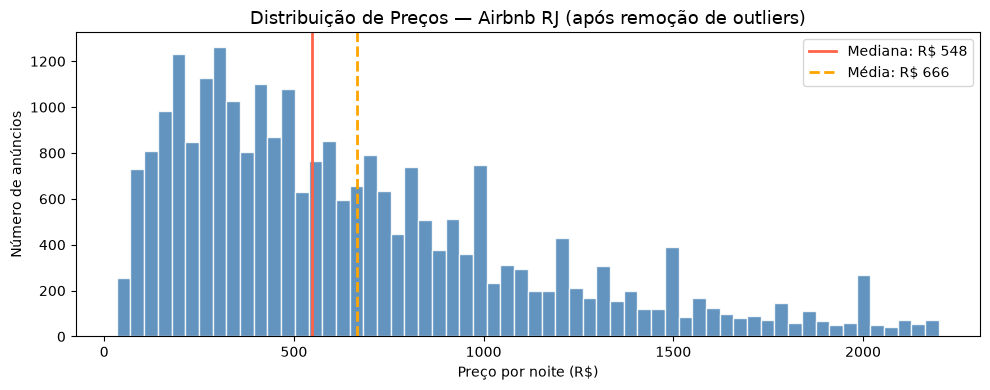


Leitura: A distribuição de preços permanece assimétrica à direita mesmo após a
remoção de outliers pelo IQR. A mediana (R$ ~548) fica abaixo da média
(R$ ~666), confirmando que uma fatia de imóveis de preço elevado ainda puxa a
média para cima. A maioria dos anúncios se concentra na faixa R$ 150–R$ 900.



In [14]:
# --- Gráfico 1: Histograma de distribuição de preços ---
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df_limpo['price'], bins=60, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(df_limpo['price'].median(), color='tomato', linewidth=2,
           label=f"Mediana: R$ {df_limpo['price'].median():,.0f}")
ax.axvline(df_limpo['price'].mean(), color='orange', linewidth=2, linestyle='--',
           label=f"Média: R$ {df_limpo['price'].mean():,.0f}")
ax.set_title('Distribuição de Preços — Airbnb RJ (após remoção de outliers)', fontsize=13)
ax.set_xlabel('Preço por noite (R$)')
ax.set_ylabel('Número de anúncios')
ax.legend()
plt.tight_layout()
plt.show()

print("""
Leitura: A distribuição de preços permanece assimétrica à direita mesmo após a
remoção de outliers pelo IQR. A mediana (R$ ~548) fica abaixo da média
(R$ ~666), confirmando que uma fatia de imóveis de preço elevado ainda puxa a
média para cima. A maioria dos anúncios se concentra na faixa R$ 150–R$ 900.
""")

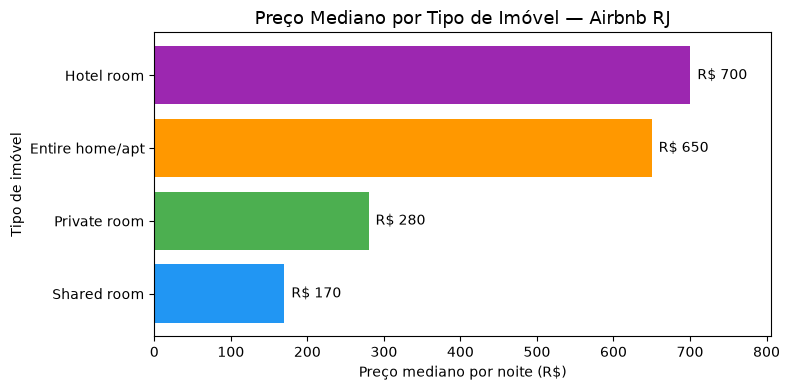


Leitura: Quartos compartilhados (Shared room) são os mais baratos em mediana,
seguidos dos quartos privados (Private room). Apartamentos inteiros e quartos de
hotel têm preços medianos semelhantes, ambos em torno de R$ 600–700. Para viajantes
com orçamento limitado, o quarto privado oferece um custo ~50% menor que o
apartamento inteiro com privacidade razoável.



In [15]:
# --- Gráfico 2: Preço mediano por tipo de imóvel ---
resumo_tipo_plot = (
    df_limpo.groupby('room_type')['price']
    .median()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(resumo_tipo_plot.index, resumo_tipo_plot.values,
               color=['#2196F3', '#4CAF50', '#FF9800', '#9C27B0'])
ax.bar_label(bars, fmt='R$ {:,.0f}', padding=5)
ax.set_title('Preço Mediano por Tipo de Imóvel — Airbnb RJ', fontsize=13)
ax.set_xlabel('Preço mediano por noite (R$)')
ax.set_ylabel('Tipo de imóvel')
ax.set_xlim(0, resumo_tipo_plot.max() * 1.15)
plt.tight_layout()
plt.show()

print("""
Leitura: Quartos compartilhados (Shared room) são os mais baratos em mediana,
seguidos dos quartos privados (Private room). Apartamentos inteiros e quartos de
hotel têm preços medianos semelhantes, ambos em torno de R$ 600–700. Para viajantes
com orçamento limitado, o quarto privado oferece um custo ~50% menor que o
apartamento inteiro com privacidade razoável.
""")

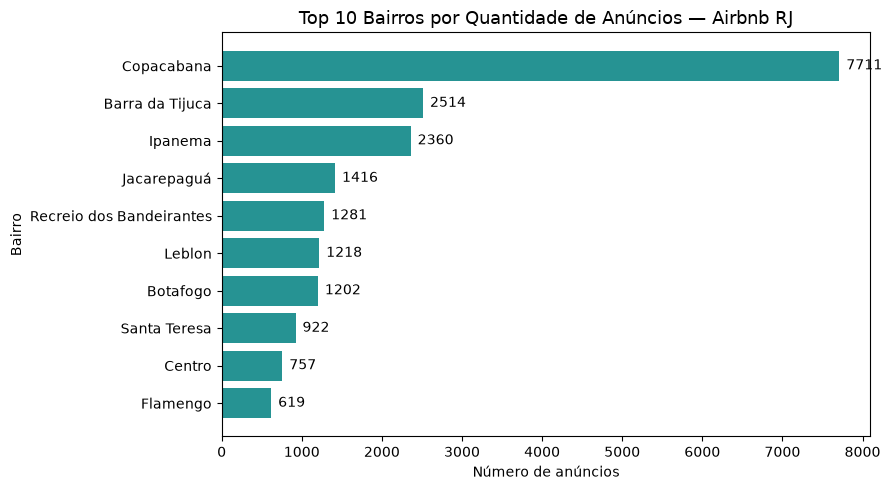


Leitura: Copacabana domina com absoluta folga, concentrando mais de 7.700 anúncios —
quase o dobro de Barra da Tijuca (2º lugar). Os três primeiros bairros juntos
(Copacabana, Barra da Tijuca e Ipanema) representam mais de 40% de todos os anúncios
da cidade. Isso indica alta liquidez e competição nesses bairros, o que pode
pressionar os preços para baixo comparado a bairros menos saturados de oferta.



In [16]:
# --- Gráfico 3: Top 10 bairros por número de anúncios ---
top10_anuncios = (
    df_limpo.groupby('neighbourhood').size()
    .nlargest(10)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top10_anuncios.index, top10_anuncios.values, color='teal', alpha=0.85)
ax.bar_label(bars, padding=5)
ax.set_title('Top 10 Bairros por Quantidade de Anúncios — Airbnb RJ', fontsize=13)
ax.set_xlabel('Número de anúncios')
ax.set_ylabel('Bairro')
plt.tight_layout()
plt.show()

print("""
Leitura: Copacabana domina com absoluta folga, concentrando mais de 7.700 anúncios —
quase o dobro de Barra da Tijuca (2º lugar). Os três primeiros bairros juntos
(Copacabana, Barra da Tijuca e Ipanema) representam mais de 40% de todos os anúncios
da cidade. Isso indica alta liquidez e competição nesses bairros, o que pode
pressionar os preços para baixo comparado a bairros menos saturados de oferta.
""")

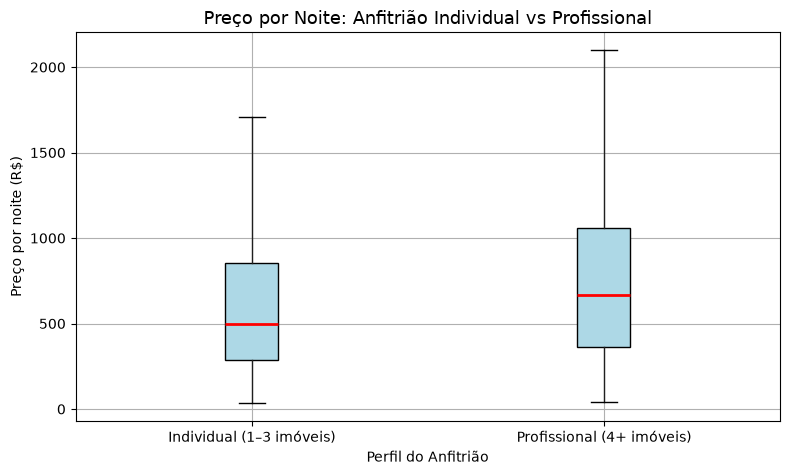

Mediana individual:   R$ 500
Mediana profissional: R$ 666

Leitura: A mediana de preço de anfitriões profissionais é ligeiramente maior,
sugerindo que gestores com múltiplos imóveis tendem a precificar acima do
mercado individual. No entanto, a dispersão (IQR) é semelhante nos dois grupos,
indicando que o perfil do anfitrião isoladamente não determina o preço —
a localização e o tipo de imóvel têm peso maior.



In [20]:
# --- Gráfico 4: Preço por perfil de anfitrião (individual vs profissional) ---
labels_host = {0: 'Individual (1–3 imóveis)', 1: 'Profissional (4+ imóveis)'}
df_plot = df_limpo.copy()
df_plot['perfil_host'] = df_plot['host_profissional'].map(labels_host)

fig, ax = plt.subplots(figsize=(8, 5))
df_plot.boxplot(
    column='price',
    by='perfil_host',
    ax=ax,
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue'),
    medianprops=dict(color='red', linewidth=2)
)
ax.set_title('Preço por Noite: Anfitrião Individual vs Profissional', fontsize=13)
ax.set_xlabel('Perfil do Anfitrião')
ax.set_ylabel('Preço por noite (R$)')
plt.suptitle('')  # remove título automático do boxplot
plt.tight_layout()
plt.show()

media_ind  = df_limpo[df_limpo['host_profissional'] == 0]['price'].median()
media_prof = df_limpo[df_limpo['host_profissional'] == 1]['price'].median()
print(f"Mediana individual:   R$ {media_ind:,.0f}")
print(f"Mediana profissional: R$ {media_prof:,.0f}")
print("""
Leitura: A mediana de preço de anfitriões profissionais é ligeiramente maior,
sugerindo que gestores com múltiplos imóveis tendem a precificar acima do
mercado individual. No entanto, a dispersão (IQR) é semelhante nos dois grupos,
indicando que o perfil do anfitrião isoladamente não determina o preço —
a localização e o tipo de imóvel têm peso maior.
""")

---
## Seção 5 — Conclusões

### 5.1 Os três achados principais

**1. O mercado é geograficamente concentrado e polarizado.**  
Copacabana sozinha responde por mais de 27% de todos os anúncios válidos. Ao mesmo tempo, Leblon e Ipanema têm preço mediano 60–70% acima de Copacabana, mesmo com menor volume de oferta. Para uma empresa que deseja entrar no mercado de gestão de imóveis, isso sugere duas estratégias distintas: escala em Copacabana ou margem alta na Zona Sul premium.

**2. O tipo de imóvel importa mais do que o perfil do anfitrião.**  
Apartamentos inteiros têm mediana de preço cerca de 2,5× maior que quartos privados. Anfitriões profissionais cobram marginalmente mais, mas a diferença é pequena. A variável que mais explica o preço é `room_type` + `neighbourhood` — não quem hospeda.

**3. 30% dos anúncios nunca receberam avaliação — um sinal de baixa atividade real.**  
A ausência de `last_review` em 8.518 anúncios indica imóveis que podem estar listados mas inativos (pouca disponibilidade, preços proibitivos ou novo cadastro). Para uma análise de demanda real, filtrar apenas imóveis com `number_of_reviews_ltm > 0` seria mais representativo.

---

### 5.2 Limitações

- **Corte temporal:** os dados refletem o estado do Airbnb em dezembro/2022. Variações sazonais (Carnaval, Copa, verão) não estão capturadas.
- **Preço ≠ Receita:** o campo `price` é o preço anunciado, não o preço praticado. Descontos, cancelamentos e ocupação real são desconhecidos.
- **Causalidade:** todas as relações observadas são correlações. Não podemos afirmar que a zona Sul *causa* preços mais altos — há variáveis de confundimento (tamanho do imóvel, amenidades, proximidade da praia).
- **Mapeamento de zonas:** a tabela auxiliar de zonas cobre apenas 26 bairros dos 152 existentes. Análises por zona devem ser interpretadas com cautela.

---

### 5.3 Próximos passos

Com mais tempo ou mais dados, investigaríamos:

1. **Sazonalidade:** cruzar com dados de ocupação mês a mês para identificar picos de demanda.
2. **Modelagem de preço:** construir um modelo de regressão usando `neighbourhood`, `room_type`, `minimum_nights` e `availability_365` como preditores.
3. **Análise de texto:** processar a coluna `name` para identificar palavras-chave associadas a preços mais altos ("vista para o mar", "cobertura", "piscina").